In [11]:
import pandas as pd

sites = deposits.copy()

# Standardize field names and clean blank spaces in text
sites.columns = sites.columns.str.strip().str.lower()

for column in sites.select_dtypes(include="object").columns:
    sites[column] = sites[column].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )
    sites[column] = sites[column].replace("", pd.NA)

# Standardize the status labels for consistency
sites["sitestatus"] = (
    sites["sitestatus"].astype("string").str.strip().str.lower()
)

# Remove records without a mapped location
before = len(sites)
sites = sites.loc[sites.geometry.notna()].copy()

print(f"Records before cleaning: {before}")
print(f"Records after cleaning:  {len(sites)}")
print(f"Records without geometry removed: {before - len(sites)}")
print("\nStatus values:")
display(sites["sitestatus"].value_counts(dropna=False))

Records before cleaning: 187
Records after cleaning:  187
Records without geometry removed: 0

Status values:


sitestatus
prospect    102
deposit      65
group        20
Name: count, dtype: Int64

Records and fields: (187, 30)

Records by site status:


,count
sitestatus,
prospect,102
deposit,65
group,20



Missing values by field (%):


,missing_percent
includes2,99.5
hangwall,94.1
group_name,89.3
includes,89.3
footwall,88.8
name_other,80.7
mineralogy,75.4
complex,62.6
tctnic_set,61.5
comments,37.4



Summary of numeric fields:


,latitude,longitude,tonnage_mt,cu_pct,co_pct,con_cu_t
count,187.00,187.00,187.00,187.00,187.00,187.00
mean,-11.38,26.86,29.84,1.32,0.14,0.81
std,0.82,0.95,103.44,1.69,0.34,2.90
min,-14.35,25.23,0.00,0.00,0.00,0.00
25%,-11.86,26.15,0.00,0.00,0.00,0.00
50%,-11.03,26.61,0.00,0.00,0.00,0.00
75%,-10.74,27.68,8.25,2.59,0.07,0.26
max,-10.51,28.82,774.77,6.59,2.31,22.44


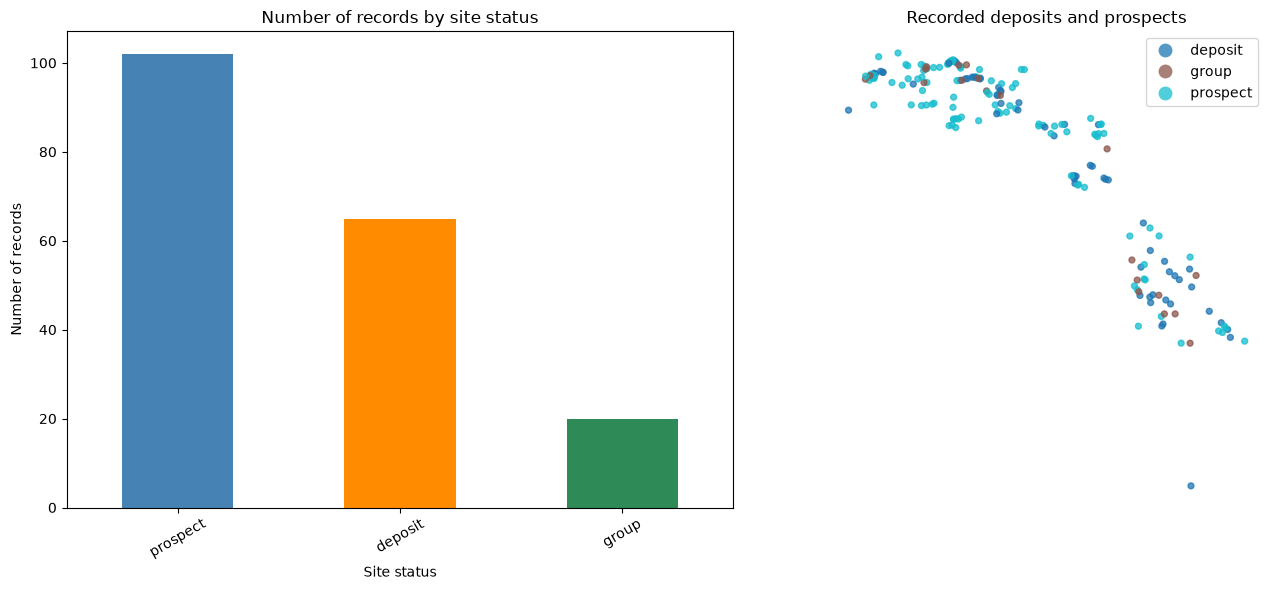

In [12]:
import matplotlib.pyplot as plt
from IPython.display import display

print("Records and fields:", sites.shape)

print("\nRecords by site status:")
display(sites["sitestatus"].value_counts().rename("count").to_frame())

print("\nMissing values by field (%):")
missing_pct = (
    sites.drop(columns="geometry")
    .isna()
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
)
display(missing_pct.to_frame("missing_percent"))

numeric_fields = sites.select_dtypes(include="number").columns
print("\nSummary of numeric fields:")
display(sites[numeric_fields].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sites["sitestatus"].value_counts().plot(
    kind="bar", ax=axes[0], color=["steelblue", "darkorange", "seagreen"]
)
axes[0].set_title("Number of records by site status")
axes[0].set_xlabel("Site status")
axes[0].set_ylabel("Number of records")
axes[0].tick_params(axis="x", rotation=30)

sites.plot(
    column="sitestatus",
    categorical=True,
    legend=True,
    markersize=18,
    alpha=0.75,
    ax=axes[1],
)
axes[1].set_title("Recorded deposits and prospects")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

Cross-validation results:


,CV macro F1,CV balanced accuracy
Random forest,0.865,0.870
Logistic regression,0.778,0.778
Support vector machine,0.739,0.739


Selected model: Random forest
PCA components retained: 33
Variance retained by PCA: 0.956

Held-out results:


,precision,recall,f1-score,support
deposit,0.750,0.923,0.828,13.000
prospect,0.944,0.810,0.872,21.000
accuracy,0.853,0.853,0.853,0.853
macro avg,0.847,0.866,0.850,34.000
weighted avg,0.870,0.853,0.855,34.000


Held-out predictions (actual vs predicted):


,actual,predicted
125,prospect,prospect
104,deposit,deposit
53,prospect,prospect
12,deposit,deposit
15,prospect,deposit
133,prospect,prospect
81,prospect,prospect
77,prospect,prospect
40,deposit,deposit
129,deposit,prospect


In [16]:
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Use individual deposit and prospect records; exclude grouped records
model_data = sites.loc[
    sites["sitestatus"].isin(["deposit", "prospect"])
].copy()

feature_columns = [
    "type",
    "subtype",
    "age_range",
    "unit",
    "hostrocks",
]

X = model_data[feature_columns]
y = model_data["sitestatus"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    StandardScaler(),
    PCA(n_components=0.95, svd_solver="full"),
    RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
    ),
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("PCA components retained:", model.named_steps["pca"].n_components_)
print("\nResults on held-out records:")
print(classification_report(y_test, predictions, zero_division=0))

display(pd.DataFrame({
    "actual": y_test,
    "predicted": predictions,
}, index=X_test.index))

PCA components retained: 33

Results on held-out records:
              precision    recall  f1-score   support

     deposit       0.75      0.92      0.83        13
    prospect       0.94      0.81      0.87        21

    accuracy                           0.85        34
   macro avg       0.85      0.87      0.85        34
weighted avg       0.87      0.85      0.85        34



,actual,predicted
125,prospect,prospect
104,deposit,deposit
53,prospect,prospect
12,deposit,deposit
15,prospect,deposit
133,prospect,prospect
81,prospect,prospect
77,prospect,prospect
40,deposit,deposit
129,deposit,prospect
